# Acupuncture annual uptake: combined or separate care settings

Choose a combined projection, or separate VAMC and Community Care odds-growth
scenarios through FY31. Reuse your patient probabilities from either clinical
model notebook. No clinical model is refitted here.

Growth can be supplied as endpoint odds multipliers or estimated from annual
historical log odds. VAMC and Community Care trends are estimated separately.
Historical extrapolation remains a planning assumption, not a statistically
established upper limit or an estimate of full-availability demand.

Counts are unique patients within a year, not visits or five-year unique users.
The supplied population and patient profiles stay fixed. A patient may use both
settings in one year; the two setting totals must not simply be added.

## 1. Imports

The notebook is standalone. If needed, uncomment the installation line, run it,
and restart the kernel. No files outside the configured inputs are required.

In [1]:
# %pip install numpy pandas matplotlib
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

## 2. Configuration

**PROJECTION_MODE**: "combined" preserves a single top-line model;
"separate" applies independent VAMC and Community Care growth multipliers.

**GROWTH_SOURCE**: "manual" uses your endpoint assumptions; "historical" fits
a straight line to annual log odds for each active setting. TREND_WINDOWS
defines alternative scenarios, with a flat reference added automatically.
Use at least three complete annual observations per window. Declining odds are
allowed; the peak may occur before FY31. No confidence interval is estimated.

For separate mode, choose a baseline source:
- **"allocate_combined"**: retain the existing overall patient probabilities and
  multiply by the observed fraction of users who used each setting. Supply
  baseline VAMC, Community Care and both-setting unique-user counts below, or
  provide the baseline FY row in HISTORY_CSV. This assumes setting mix is the same
  across all patient profiles; it does not learn separate setting preferences.
- **"setting_probabilities"**: supply probability_vamc and
  probability_community_care columns from separately fitted, validated models.
  Optional probability_both describes use in both settings. Observed 0/1 use
  flags are not substitutes for predictive probability columns.

OVERLAP_METHOD defaults to **"bounds_only"**: report separate setting counts and
feasible limits on their combined unique count, with no combined point estimate.
Optional **"fixed_overlap_fraction"** holds baseline P(both)/min(P(VAMC), P(CC))
fixed for each patient, increasing overlap only when needed for valid
probabilities. This is an explicit additional assumption, not a fitted overlap
forecast. It requires known baseline overlap. Zero baseline overlap does not
guarantee zero future overlap.

The six historical columns and source aliases are documented below. If only
separate totals are available and overlap is unknown, use setting-specific
probabilities with bounds_only. Do not fill unknown overlap with zero.

In [18]:
INPUT_CSV = Path(r"C:\Users\VACOGRAUPE\OneDrive - Department of Veterans Affairs\Desktop\acupuncture_python_code\acupuncture_evidence_outputs\patient_analysis_conditions_presence\patient_probabilities.csv")
ID_COLUMN = None  # Auto-detect patientICN or PatientICN.
PROJECTION_MODE = "separate"  # "combined" or "separate"
GROWTH_SOURCE = "historical"  # "manual" or "historical"
PROBABILITY_COLUMN = "probability_oof"
SETTING_PROBABILITY_COLUMNS = {
    "vamc": "probability_vamc",
    "community_care": "probability_community_care",
    "both": "probability_both",  # Optional; can be None.
}
SEPARATE_BASELINE_SOURCE = "allocate_combined"
OVERLAP_METHOD = "bounds_only"  # Or "fixed_overlap_fraction".

BASELINE_FY = 2026
FORECAST_FYS = [2027, 2028, 2029, 2030, 2031, 2032, 2033, 2034, 2035, 2036]
FY31_ODDS_MULTIPLIERS = {
    "Reference: unchanged uptake": 1.0,
    "Illustrative 2x odds": 2.0,
    "Illustrative 4x odds": 4.0,
}
SEPARATE_FY31_ODDS_MULTIPLIERS = {
    "Reference: unchanged uptake": {"vamc": 1.0, "community_care": 1.0},
    "Illustrative differential growth": {"vamc": 1.5, "community_care": 2.5},
}
HISTORY_CSV = Path(r"C:\Users\VACOGRAUPE\OneDrive - Department of Veterans Affairs\Desktop\acupuncture_python_code\annual_acupuncture_user_history.csv")
HISTORY_COLUMN_MAP = {
    # Canonical name: your source column name, for example:
    # "fiscal_year": "Fiscal Year", "population": "Enrollees",
}
TREND_WINDOWS = {
    "Historical trend: FY21 onward": 2021,
    "Recent trend: FY24 onward": 2024,
}
# Used only if no baseline FY setting mix is available from HISTORY_CSV.
# All are unique users in the SAME year/population; both is an intersection.
BASELINE_SETTING_COUNTS = {"vamc": None, "community_care": None, "both": None}

OUTPUT_BASE = Path.cwd() / "acupuncture_uptake_poc_outputs"
run_name = "input_data"
run_name += "_" + PROJECTION_MODE + "_" + GROWTH_SOURCE
if PROJECTION_MODE == "separate":
    run_name += "_" + SEPARATE_BASELINE_SOURCE + "_" + OVERLAP_METHOD
OUTPUT_DIR = OUTPUT_BASE / run_name
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 3. Projection and historical-trend helpers

For each setting, baseline probability p and odds multiplier m give:
**future probability = m p / (1 - p + m p)**.

The historical option regresses log(users / (population - users)) on fiscal year,
giving annual odds ratio exp(slope). The FY31 multiplier is exp(5 × slope) for
an FY26 baseline. The slope is anchored to each supplied baseline probability,
rather than replacing the baseline level with the fitted historical level.
Annual observations are equally weighted; repeated patients across years are
not independent observations for inference, and no inferential intervals are
computed.

Separate binary setting models can overlap. Combined unique users equal VAMC
users + Community Care users - users in both. Without an overlap assumption,
patient-level combined probability lies between max(pV, pC) and min(1, pV + pC).
These are overlap feasibility limits, not forecast uncertainty intervals.

In [19]:
"""Pure helpers for combined or VAMC/Community Care annual odds scenarios."""
from __future__ import annotations
import numpy as np
import pandas as pd

SETTINGS = ("combined", "vamc", "community_care")
COUNT_COLUMNS = {
    "combined": "users_combined",
    "vamc": "users_vamc",
    "community_care": "users_community_care",
}

def probability_array(values, name):
    result = pd.to_numeric(pd.Series(values), errors="raise").to_numpy(dtype=float)
    if not len(result) or not np.isfinite(result).all() or ((result < 0) | (result > 1)).any():
        raise ValueError(f"{name} needs finite probabilities between 0 and 1.")
    return result

def uplift_probability(probability, odds_multiplier):
    """Shift odds while preserving 0 and 1; positive multipliers may grow or decline."""
    values = np.asarray(probability, dtype=float)
    if not np.isfinite(odds_multiplier) or odds_multiplier <= 0:
        raise ValueError("An odds multiplier must be finite and greater than zero.")
    # Stable on each side of 1, including large multipliers.
    if odds_multiplier >= 1:
        return values / (values + (1 - values) / odds_multiplier)
    return odds_multiplier * values / (1 - values + odds_multiplier * values)

def validate_history(history, settings, baseline_fy):
    required = ["fiscal_year", "population"] + [COUNT_COLUMNS[s] for s in settings]
    missing = set(required) - set(history)
    if missing:
        raise ValueError(f"Historical CSV is missing: {sorted(missing)}")
    result = history.copy()
    columns = ["fiscal_year", "population"] + [
        c for c in ["users_combined", "users_vamc", "users_community_care", "users_both"] if c in result
    ]
    for col in columns:
        result[col] = pd.to_numeric(result[col], errors="raise")
        if not np.isfinite(result[col]).all() or not np.equal(result[col], np.floor(result[col])).all():
            raise ValueError(f"{col} must contain finite integer counts/years without missing values.")
    if result["fiscal_year"].duplicated().any():
        raise ValueError("Historical data need one row per fiscal year.")
    if result["population"].le(0).any():
        raise ValueError("Historical population must be positive.")
    if result["fiscal_year"].gt(baseline_fy).any():
        raise ValueError("Historical data must end by the baseline FY; future outcomes cannot enter the trend.")
    for col in columns[2:]:
        if ((result[col] < 0) | (result[col] > result["population"])).any():
            raise ValueError(f"{col} must lie between zero and the common population denominator.")
    if {"users_vamc", "users_community_care", "users_both"} <= set(result):
        lower = np.maximum(0, result["users_vamc"] + result["users_community_care"] - result["population"])
        upper = np.minimum(result["users_vamc"], result["users_community_care"])
        if ((result["users_both"] < lower) | (result["users_both"] > upper)).any():
            raise ValueError("Historical users_both is incompatible with the setting counts/population.")
        union = result["users_vamc"] + result["users_community_care"] - result["users_both"]
        if "users_combined" in result and not np.array_equal(result["users_combined"], union):
            raise ValueError("Combined users must equal VAMC + Community Care - users_both.")
        result["users_combined"] = union
    elif {"users_combined", "users_vamc", "users_community_care"} <= set(result):
        overlap = result["users_vamc"] + result["users_community_care"] - result["users_combined"]
        if ((overlap < 0) | (overlap > np.minimum(result["users_vamc"], result["users_community_care"]))).any():
            raise ValueError("Combined users are incompatible with the setting counts.")
        result["users_both"] = overlap
    return result.sort_values("fiscal_year").reset_index(drop=True)

def historical_odds_scenarios(history, settings, baseline_fy, last_fy, windows):
    """Unweighted OLS of annual log odds on FY, not a binomial patient-level fit."""
    scenarios = {"Reference: unchanged uptake": {s: 1.0 for s in settings}}
    reports, fitted = [], []
    for label, start_fy in windows.items():
        if label in scenarios:
            raise ValueError("Trend scenario labels must be unique and not use the reference label.")
        selected = history.loc[history["fiscal_year"].ge(start_fy)].copy()
        if len(selected) < 3:
            raise ValueError(f"{label}: need at least three complete annual observations.")
        endpoint = {}
        x = selected["fiscal_year"].to_numpy(dtype=float) - baseline_fy
        design = np.column_stack([np.ones(len(x)), x])
        for setting in settings:
            rate = selected[COUNT_COLUMNS[setting]].to_numpy(dtype=float) / selected["population"].to_numpy(dtype=float)
            if ((rate <= 0) | (rate >= 1)).any():
                raise ValueError(f"{label}, {setting}: log odds require rates strictly between 0 and 1. "
                                 "Use a justified later window or manual multiplier; no pseudocount is added.")
            log_odds = np.log(rate) - np.log1p(-rate)
            intercept, slope = np.linalg.lstsq(design, log_odds, rcond=None)[0]
            multiplier = float(np.exp(slope * (last_fy - baseline_fy)))
            if not np.isfinite(multiplier) or multiplier <= 0:
                raise ValueError("Historical trend implies an unrepresentable multiplier.")
            endpoint[setting] = multiplier
            reports.append({
                "scenario": label, "setting": setting, "first_FY": int(selected["fiscal_year"].min()),
                "last_FY": int(selected["fiscal_year"].max()), "annual_observations": len(selected),
                "log_odds_intercept_at_baseline_FY": float(intercept),
                "annual_log_odds_slope": float(slope),
                "annual_odds_ratio": float(np.exp(slope)),
                "annual_odds_change_percent": float(100 * np.expm1(slope)),
                "endpoint_FY": last_fy, "endpoint_odds_multiplier": multiplier,
                "method": "Unweighted OLS across annual log odds; descriptive extrapolation.",
            })
            for fy, observed, fitted_log in zip(selected["fiscal_year"], rate, design @ [intercept, slope]):
                fitted.append({"scenario": label, "setting": setting, "fiscal_year": int(fy),
                               "observed_use_rate": float(observed),
                               "fitted_use_rate": float(1 / (1 + np.exp(-fitted_log)))})
        scenarios[label] = endpoint
    if not windows:
        raise ValueError("Supply at least one historical trend window.")
    return scenarios, pd.DataFrame(reports), pd.DataFrame(fitted)

def baseline_setting_mix(vamc, community_care, both):
    values = np.array([vamc, community_care, both], dtype=float)
    if not np.isfinite(values).all() or (values < 0).any() or both > min(vamc, community_care):
        raise ValueError("Baseline setting counts need nonnegative VAMC/CC counts and valid users_both.")
    union = vamc + community_care - both
    if union <= 0:
        raise ValueError("Baseline setting mix needs at least one unique user.")
    return {"vamc": float(vamc / union), "community_care": float(community_care / union),
            "both": float(both / union)}

def prepare_baseline(data, mode, probability_columns, source="allocate_combined", setting_mix=None):
    if mode == "combined":
        return {"combined": probability_array(data[probability_columns["combined"]], "combined")}, None
    if mode != "separate":
        raise ValueError('PROJECTION_MODE must be "combined" or "separate".')
    if source == "allocate_combined":
        if setting_mix is None:
            raise ValueError("Allocating combined probabilities requires baseline setting counts, including overlap.")
        p = probability_array(data[probability_columns["combined"]], "combined")
        result = {s: p * setting_mix[s] for s in ["vamc", "community_care"]}
        both = p * setting_mix["both"]
    elif source == "setting_probabilities":
        result = {s: probability_array(data[probability_columns[s]], s) for s in ["vamc", "community_care"]}
        both_column = probability_columns.get("both")
        both = probability_array(data[both_column], "both") if both_column and both_column in data else None
    else:
        raise ValueError('SEPARATE_BASELINE_SOURCE must be "allocate_combined" or "setting_probabilities".')
    if both is not None:
        lower = np.maximum(0, result["vamc"] + result["community_care"] - 1)
        upper = np.minimum(result["vamc"], result["community_care"])
        if ((both < lower - 1e-10) | (both > upper + 1e-10)).any():
            raise ValueError("Baseline both-setting probabilities violate the valid overlap limits.")
    return result, both

def project_uptake(baseline, both, scenarios, baseline_fy, forecast_fys, overlap_method="bounds_only"):
    if not forecast_fys or sorted(set(forecast_fys)) != list(forecast_fys):
        raise ValueError("Forecast FYs must be nonempty, distinct and increasing.")
    if any(not isinstance(fy, (int, np.integer)) for fy in forecast_fys) or min(forecast_fys) <= baseline_fy:
        raise ValueError("Forecast FYs must be integer years after the baseline FY.")
    settings = list(baseline)
    n = len(next(iter(baseline.values())))
    if not n or any(len(p) != n for p in baseline.values()):
        raise ValueError("All baseline probabilities need the same nonempty patient roster.")
    if set(settings) not in [{"combined"}, {"vamc", "community_care"}]:
        raise ValueError("Baseline needs either combined probabilities or both setting probabilities.")
    if not scenarios:
        raise ValueError("At least one growth scenario is needed.")
    if overlap_method not in {"bounds_only", "fixed_overlap_fraction"}:
        raise ValueError("OVERLAP_METHOD must be bounds_only or fixed_overlap_fraction.")
    if set(settings) != {"combined"} and overlap_method == "fixed_overlap_fraction" and both is None:
        raise ValueError("Fixed overlap needs baseline both-setting probabilities or setting-mix counts.")
    alpha = None
    if both is not None and set(settings) != {"combined"}:
        smaller = np.minimum(baseline["vamc"], baseline["community_care"])
        alpha = np.divide(both, smaller, out=np.zeros_like(smaller, dtype=float), where=smaller > 0)
    records, overlaps = [], []
    for scenario, endpoints in scenarios.items():
        if set(endpoints) != set(settings):
            raise ValueError(f"{scenario}: supply one endpoint odds multiplier for each active setting.")
        for endpoint in endpoints.values():
            if not np.isfinite(endpoint) or endpoint <= 0:
                raise ValueError("Endpoint odds multipliers must be finite and positive; declines are allowed.")
        for fy in forecast_fys:
            fraction = (fy - baseline_fy) / (max(forecast_fys) - baseline_fy)
            shifted = {}
            for setting in settings:
                multiplier = float(np.exp(np.log(endpoints[setting]) * fraction))
                shifted[setting] = uplift_probability(baseline[setting], multiplier)
                expected = float(shifted[setting].sum())
                records.append({
                    "scenario": scenario, "fiscal_year": fy, "setting": setting,
                    "assumed_odds_multiplier": multiplier, "population": n,
                    "baseline_expected_users": float(np.sum(baseline[setting])),
                    "expected_annual_users": expected, "expected_annual_use_rate": expected / n,
                    "additional_users_vs_baseline": expected - float(np.sum(baseline[setting])),
                })
            if set(settings) == {"combined"}:
                continue
            v, c = shifted["vamc"], shifted["community_care"]
            # Bounds on patient-level P(V union C); no independence assumption.
            lower = np.maximum(v, c)
            upper = np.minimum(1, v + c)
            unique, overlap, adjusted = None, None, None
            if overlap_method == "fixed_overlap_fraction":
                raw_both = alpha * np.minimum(v, c)
                future_both = np.maximum(raw_both, np.maximum(0, v + c - 1))
                adjusted = int(np.sum(future_both > raw_both + 1e-12))
                unique = float(np.sum(v + c - future_both))
                overlap = float(future_both.sum())
            overlaps.append({
                "scenario": scenario, "fiscal_year": fy, "population": n,
                "combined_unique_lower_bound": float(lower.sum()),
                "combined_unique_upper_bound": float(upper.sum()),
                "combined_expected_users_under_overlap_assumption": unique,
                "expected_users_both_under_overlap_assumption": overlap,
                "patients_requiring_overlap_constraint_adjustment": adjusted,
                "overlap_method": overlap_method,
                "interpretation": "Overlap feasibility limits; not confidence/prediction intervals.",
            })
    return pd.DataFrame(records), pd.DataFrame(overlaps)

def summarize_peaks(annual):
    rows = []
    for (scenario, setting), group in annual.groupby(["scenario", "setting"], sort=False):
        peak = float(group["expected_annual_users"].max())
        years = group.loc[np.isclose(group["expected_annual_users"], peak, rtol=0, atol=1e-8), "fiscal_year"]
        rows.append({"scenario": scenario, "setting": setting, "peak_annual_users": peak,
                     "peak_annual_use_rate": peak / int(group["population"].iloc[0]),
                     "peak_years": ", ".join("FY" + str(int(y)) for y in years)})
    return pd.DataFrame(rows)

## 4. Input data

Patient CSV: one row per baseline patient, with a unique ID and the probability
column(s) for the selected mode. Supply the full population denominator, not just
current users. Diagnosis rows or stacked fiscal years are not valid inputs here.

Historical CSV: one row per fiscal year, same denominator definition throughout:
- fiscal_year, population
- users_combined: distinct users in either setting, for combined trends
- users_vamc, users_community_care: distinct users within each setting
- users_both: distinct users who used BOTH that year, when known

For separate trends, the two setting count columns are required. Supplying
users_combined or users_both additionally identifies historical overlap; when
both are supplied their identity is checked. Omit unknown optional columns
instead of filling them with zeros or blank cells. Do not use claims/visits.

Use complete FYs with comparable coding, claims capture and enrollment definitions.
If historical enrollees differ from the probability-model cohort, applying those
growth trends or setting shares to the cohort is a transfer assumption. The
notebook flags denominator differences; matching counts alone cannot prove
matching populations. The fitted growth reflects adoption, access, coding and
population changes together, not a causal access effect.

In [20]:
if PROJECTION_MODE not in {"combined", "separate"}:
    raise ValueError("PROJECTION_MODE must be combined or separate.")
if GROWTH_SOURCE not in {"manual", "historical"}:
    raise ValueError("GROWTH_SOURCE must be manual or historical.")

header = pd.read_csv(INPUT_CSV, nrows=0).columns.tolist()
id_column = ID_COLUMN or next((c for c in ["patientICN", "PatientICN"] if c in header), None)
if id_column is None:
    raise ValueError("Set ID_COLUMN to the input's unique patient identifier.")
columns = [id_column]
if PROJECTION_MODE == "combined" or SEPARATE_BASELINE_SOURCE == "allocate_combined":
    columns.append(PROBABILITY_COLUMN)
else:
    columns += [SETTING_PROBABILITY_COLUMNS[s] for s in ["vamc", "community_care"]]
    if SETTING_PROBABILITY_COLUMNS.get("both") in header:
        columns.append(SETTING_PROBABILITY_COLUMNS["both"])
data = pd.read_csv(INPUT_CSV, usecols=list(dict.fromkeys(columns)), dtype={id_column: "string"})
history = None
if HISTORY_CSV is not None:
    history = pd.read_csv(HISTORY_CSV)
    history = history.rename(columns={source: canonical for canonical, source in HISTORY_COLUMN_MAP.items()})
    if history.columns.duplicated().any():
        raise ValueError("Historical column mapping created duplicate columns.")

identifiers = data[id_column].astype("string").str.strip()
if data.empty or identifiers.isna().any() or identifiers.eq("").any() or identifiers.duplicated().any():
    raise ValueError("Input needs one nonmissing, unique identifier per baseline person.")
settings = ["combined"] if PROJECTION_MODE == "combined" else ["vamc", "community_care"]
if history is not None:
    history = validate_history(history, settings, BASELINE_FY)
if GROWTH_SOURCE == "historical" and history is None:
    raise ValueError("Set HISTORY_CSV for historical odds growth.")

setting_mix = None
mix_source = None
if PROJECTION_MODE == "separate" and SEPARATE_BASELINE_SOURCE == "allocate_combined":
    baseline_row = history.loc[history["fiscal_year"].eq(BASELINE_FY)] if history is not None else pd.DataFrame()
    if len(baseline_row) and {"users_vamc", "users_community_care", "users_both"} <= set(baseline_row):
        row = baseline_row.iloc[0]
        setting_mix = baseline_setting_mix(row["users_vamc"], row["users_community_care"], row["users_both"])
        mix_source = "Baseline FY historical unique-user counts"
    elif all(BASELINE_SETTING_COUNTS.get(s) is not None for s in ["vamc", "community_care", "both"]):
        setting_mix = baseline_setting_mix(**BASELINE_SETTING_COUNTS)
        mix_source = "Supplied baseline unique-user counts"
    else:
        raise ValueError("Allocating overall probabilities requires baseline VAMC/CC counts AND overlap. "
                         "Supply them in HISTORY_CSV or BASELINE_SETTING_COUNTS. "
                         "Otherwise use setting_probabilities with bounds_only.")
probability_columns = {"combined": PROBABILITY_COLUMN, **SETTING_PROBABILITY_COLUMNS}
baseline, baseline_both = prepare_baseline(
    data, PROJECTION_MODE, probability_columns, SEPARATE_BASELINE_SOURCE, setting_mix,
)
n_patients = len(data)
mode_label = "SUPPLIED BASELINE PROBABILITIES"
baseline_rows = [{"setting": s, "patients": n_patients, "baseline_expected_users": float(p.sum()),
                  "baseline_use_rate": float(p.mean())} for s, p in baseline.items()]
if PROJECTION_MODE == "separate" and baseline_both is not None:
    union = baseline["vamc"] + baseline["community_care"] - baseline_both
    baseline_rows += [{"setting": "combined_unique", "patients": n_patients,
                       "baseline_expected_users": float(union.sum()), "baseline_use_rate": float(union.mean())}]
baseline_summary = pd.DataFrame(baseline_rows)
historical_baseline_population = None
if history is not None and history["fiscal_year"].eq(BASELINE_FY).any():
    historical_baseline_population = int(history.loc[history["fiscal_year"].eq(BASELINE_FY), "population"].iloc[0])
    if historical_baseline_population != n_patients:
        print("Historical baseline denominator differs from the scored cohort:",
              historical_baseline_population, "vs", n_patients,
              ". Transferring growth/mix is an additional assumption.")
print(mode_label)
print("Projection mode:", PROJECTION_MODE, "; growth source:", GROWTH_SOURCE)
display(baseline_summary)
if setting_mix is not None:
    print("Setting mix source:", mix_source, "; shares conditional on any use:", setting_mix)

Historical baseline denominator differs from the scored cohort: 5233835 vs 5231037 . Transferring growth/mix is an additional assumption.
SUPPLIED BASELINE PROBABILITIES
Projection mode: separate ; growth source: historical


,setting,patients,baseline_expected_users,baseline_use_rate
0,vamc,5231037,116317.836711,0.022236
1,community_care,5231037,104011.291896,0.019883
2,combined_unique,5231037,206881.962848,0.039549


Setting mix source: Baseline FY historical unique-user counts ; shares conditional on any use: {'vamc': 0.562242522790733, 'community_care': 0.5027566950000237, 'both': 0.06499921779075665}


## 5. Select or estimate separate growth rates

The historical report shows the fitted annual odds change for each setting and
window, along with the resulting endpoint multiplier. It does not estimate
patient transitions, switching between settings, capacity, or latent demand.

The scenario label pairs VAMC and Community Care growth from the same selected
historical period. Manual mode instead lets you pair any explicit assumptions.
A 2x odds multiplier does not double probability.

In [21]:
growth_report = pd.DataFrame()
historical_fit = pd.DataFrame()
if GROWTH_SOURCE == "historical":
    scenarios, growth_report, historical_fit = historical_odds_scenarios(
        history, settings, BASELINE_FY, max(FORECAST_FYS), TREND_WINDOWS,
    )
    display(growth_report)
else:
    scenarios = ({label: {"combined": value} for label, value in FY31_ODDS_MULTIPLIERS.items()}
                 if PROJECTION_MODE == "combined" else SEPARATE_FY31_ODDS_MULTIPLIERS)
    display(pd.DataFrame([{"scenario": label, **values} for label, values in scenarios.items()]))

annual, overlaps = project_uptake(
    baseline, baseline_both, scenarios, BASELINE_FY, FORECAST_FYS, OVERLAP_METHOD,
)
print(mode_label)
display(annual.pivot(index="fiscal_year", columns=["setting", "scenario"], values="expected_annual_users").round())
if not overlaps.empty:
    print("Combined UNIQUE users: overlap limits and any explicitly assumed point estimate.")
    display(overlaps)

,scenario,setting,first_FY,last_FY,annual_observations,log_odds_intercept_at_baseline_FY,annual_log_odds_slope,annual_odds_ratio,annual_odds_change_percent,endpoint_FY,endpoint_odds_multiplier,method
0,Historical trend: FY21 onward,vamc,2021,2026,6,-3.632868,0.118097,1.125353,12.535284,2036,3.257520,Unweighted OLS across annual log odds; descrip...
1,Historical trend: FY21 onward,community_care,2021,2026,6,-3.891669,0.053261,1.054704,5.470449,2036,1.703366,Unweighted OLS across annual log odds; descrip...
2,Recent trend: FY24 onward,vamc,2024,2026,3,-3.751999,-0.007188,0.992838,-0.716223,2036,0.930643,Unweighted OLS across annual log odds; descrip...
3,Recent trend: FY24 onward,community_care,2024,2026,3,-3.907771,0.050116,1.051393,5.139319,2036,1.650637,Unweighted OLS across annual log odds; descrip...


SUPPLIED BASELINE PROBABILITIES


setting,vamc,community_care,vamc,community_care,vamc,community_care
scenario,Reference: unchanged uptake,Reference: unchanged uptake,Historical trend: FY21 onward,Historical trend: FY21 onward,Recent trend: FY24 onward,Recent trend: FY24 onward
fiscal_year,,,,,,
2027,116318.0,104011.0,129686.0,109300.0,115547.0,108981.0
2028,116318.0,104011.0,144470.0,114839.0,114781.0,114172.0
2029,116318.0,104011.0,160798.0,120641.0,114020.0,119594.0
2030,116318.0,104011.0,178804.0,126716.0,113264.0,125256.0
2031,116318.0,104011.0,198629.0,133074.0,112512.0,131167.0
2032,116318.0,104011.0,220424.0,139727.0,111765.0,137336.0
2033,116318.0,104011.0,244344.0,146687.0,111023.0,143773.0
2034,116318.0,104011.0,270551.0,153966.0,110285.0,150488.0


Combined UNIQUE users: overlap limits and any explicitly assumed point estimate.


,scenario,fiscal_year,population,combined_unique_lower_bound,combined_unique_upper_bound,combined_expected_users_under_overlap_assumption,expected_users_both_under_overlap_assumption,patients_requiring_overlap_constraint_adjustment,overlap_method,interpretation
0,Reference: unchanged uptake,2027,5231037,116317.836711,220328.993688,None,None,None,bounds_only,Overlap feasibility limits; not confidence/pre...
1,Reference: unchanged uptake,2028,5231037,116317.836711,220328.993688,None,None,None,bounds_only,Overlap feasibility limits; not confidence/pre...
2,Reference: unchanged uptake,2029,5231037,116317.836711,220328.993688,None,None,None,bounds_only,Overlap feasibility limits; not confidence/pre...
3,Reference: unchanged uptake,2030,5231037,116317.836711,220328.993688,None,None,None,bounds_only,Overlap feasibility limits; not confidence/pre...
4,Reference: unchanged uptake,2031,5231037,116317.836711,220328.993688,None,None,None,bounds_only,Overlap feasibility limits; not confidence/pre...
5,Reference: unchanged uptake,2032,5231037,116317.836711,220328.993688,None,None,None,bounds_only,Overlap feasibility limits; not confidence/pre...
6,Reference: unchanged uptake,2033,5231037,116317.836711,220328.993688,None,None,None,bounds_only,Overlap feasibility limits; not confidence/pre...
7,Reference: unchanged uptake,2034,5231037,116317.836711,220328.993688,None,None,None,bounds_only,Overlap feasibility limits; not confidence/pre...
8,Reference: unchanged uptake,2035,5231037,116317.836711,220328.993688,None,None,None,bounds_only,Overlap feasibility limits; not confidence/pre...
9,Reference: unchanged uptake,2036,5231037,116317.836711,220328.993688,None,None,None,bounds_only,Overlap feasibility limits; not confidence/pre...


## 6. Peak annual counts

Report the highest annual expected count for each scenario and setting.
The largest tested scenario is a conditional planning estimate. It is not a
statistical upper prediction limit or a five-year count of distinct people.

When separate mode has no overlap point assumption, the combined result is an
interval of feasible totals only. Its upper endpoint describes possible overlap
arrangements given the setting probabilities, not a likely upper utilization
forecast. Without modeling future capacity/willingness, no version here identifies
a full-availability maximum.

,scenario,setting,peak_annual_users,peak_annual_use_rate,peak_years
0,Reference: unchanged uptake,vamc,116317.836711,0.022236,"FY2027, FY2028, FY2029, FY2030, FY2031, FY2032..."
1,Reference: unchanged uptake,community_care,104011.291896,0.019883,"FY2027, FY2028, FY2029, FY2030, FY2031, FY2032..."
2,Historical trend: FY21 onward,vamc,330499.876878,0.063181,FY2036
3,Historical trend: FY21 onward,community_care,169530.732759,0.032409,FY2036
4,Recent trend: FY24 onward,vamc,115547.203641,0.022089,FY2027
5,Recent trend: FY24 onward,community_care,164792.262739,0.031503,FY2036


,scenario,highest_combined_feasible_lower_bound,highest_combined_feasible_upper_bound,highest_combined_expected_under_overlap_assumption
0,Reference: unchanged uptake,116317.836711,220328.993688,NaN
1,Historical trend: FY21 onward,330499.876878,499180.672734,NaN
2,Recent trend: FY24 onward,164792.262739,273604.458653,NaN


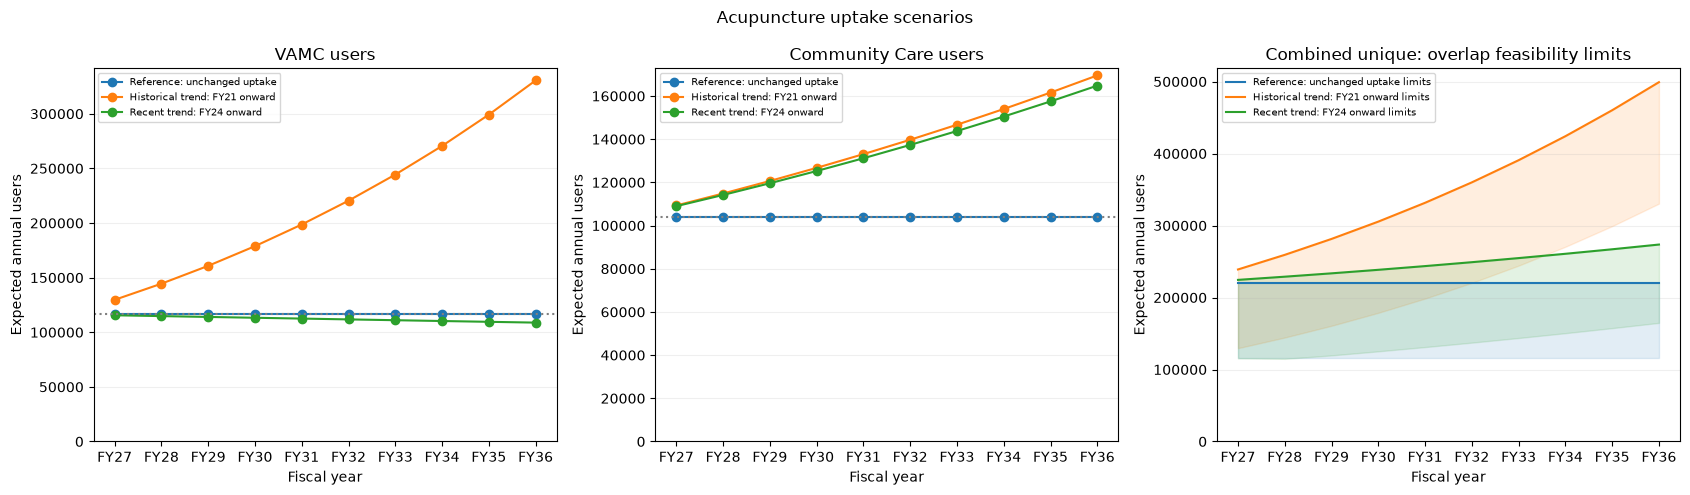

In [22]:
peak_summary = summarize_peaks(annual)
display(peak_summary)
combined_overlap_peak = None
if not overlaps.empty:
    combined_overlap_peak = overlaps.groupby("scenario", sort=False).agg(
        highest_combined_feasible_lower_bound=("combined_unique_lower_bound", "max"),
        highest_combined_feasible_upper_bound=("combined_unique_upper_bound", "max"),
        highest_combined_expected_under_overlap_assumption=("combined_expected_users_under_overlap_assumption", "max"),
    ).reset_index()
    display(combined_overlap_peak)

panels = ["combined"] if PROJECTION_MODE == "combined" else ["vamc", "community_care", "combined_unique"]
fig, axes = plt.subplots(1, len(panels), figsize=(8 if len(panels) == 1 else 17, 5), squeeze=False)
for ax, setting in zip(axes[0], panels):
    if setting == "combined_unique":
        for scenario, group in overlaps.groupby("scenario", sort=False):
            line, = ax.plot(group["fiscal_year"], group["combined_unique_upper_bound"], label=scenario + " limits")
            ax.fill_between(group["fiscal_year"], group["combined_unique_lower_bound"],
                            group["combined_unique_upper_bound"], color=line.get_color(), alpha=.13)
            if OVERLAP_METHOD == "fixed_overlap_fraction":
                ax.plot(group["fiscal_year"], group["combined_expected_users_under_overlap_assumption"],
                        "--", color=line.get_color(), label=scenario + " overlap assumption")
        title = "Combined unique: overlap feasibility limits"
    else:
        for scenario, group in annual.loc[annual["setting"].eq(setting)].groupby("scenario", sort=False):
            ax.plot(group["fiscal_year"], group["expected_annual_users"], marker="o", label=scenario)
        ax.axhline(float(baseline[setting].sum()), color="gray", linestyle=":")
        title = {"combined": "Combined unique users", "vamc": "VAMC users",
                 "community_care": "Community Care users"}[setting]
    ax.set_xticks(FORECAST_FYS, [f"FY{str(y)[-2:]}" for y in FORECAST_FYS])
    ax.set(title=title, xlabel="Fiscal year", ylabel="Expected annual users", ylim=(0, None))
    ax.grid(axis="y", alpha=.2)
    ax.legend(fontsize=7)
fig.suptitle("Acupuncture uptake scenarios")
fig.tight_layout()
plt.show()

## 7. Save aggregate results and assumptions

Mode-specific folders preserve combined and separate runs. No patient-level
scenario output is exported. Empty input templates are also saved for preparing
your real data. Expected counts may be fractional; round only for presentation.

In [23]:
assumptions = {
    "data_mode": "input_data",
    "projection_mode": PROJECTION_MODE, "growth_source": GROWTH_SOURCE,
    "baseline_FY": BASELINE_FY, "forecast_FYs": FORECAST_FYS,
    "patients": n_patients, "endpoint_odds_multipliers": scenarios,
    "separate_baseline_source": SEPARATE_BASELINE_SOURCE if PROJECTION_MODE == "separate" else None,
    "setting_mix": setting_mix, "setting_mix_source": mix_source,
    "historical_baseline_population": historical_baseline_population,
    "historical_denominator_differs": historical_baseline_population is not None and historical_baseline_population != n_patients,
    "overlap_method": OVERLAP_METHOD if PROJECTION_MODE == "separate" else None,
    "overlap_known_at_baseline": baseline_both is not None,
    "baseline_expected_users_by_setting": {row["setting"]: row["baseline_expected_users"] for row in baseline_rows},
    "highest_tested_peak_by_setting": {s: float(g["peak_annual_users"].max()) for s, g in peak_summary.groupby("setting")},
    "definition": "Highest conditional expected annual count in tested scenarios; overlap limits are not prediction intervals.",
    "assumptions": [
        "Broad eligibility is accepted; population and patient profiles stay fixed.",
        "Historical log-odds slopes, if used, are extrapolated from annual observations and anchored to supplied baseline probabilities.",
        "Combined-probability allocation, if used, assumes identical setting mix across patient profiles.",
        "VAMC and Community Care counts can overlap and must not be added to count unique people.",
        "Any fixed future overlap fraction is an assumption, not an estimated switching or overlap process.",
        "Counts are not visits and must not be summed across fiscal years for unique five-year users.",
        "Calibration and representative sampling remain necessary for useful probability sums.",
        "No deaths, entry/exit, population growth, access intervention, capacity constraints or uncertainty intervals are modeled.",
    ],
    "data_insufficient": [
        "Full-availability demand, willingness and setting-specific patient preferences when probabilities are allocated.",
        "Clinical validity, decision impact, patient benefit and resource optimization.",
    ],
}
baseline_summary.to_csv(OUTPUT_DIR / "baseline_summary.csv", index=False)
annual.to_csv(OUTPUT_DIR / "annual_uptake_scenarios.csv", index=False)
peak_summary.to_csv(OUTPUT_DIR / "scenario_peak_summary.csv", index=False)
if not overlaps.empty:
    overlaps.to_csv(OUTPUT_DIR / "setting_overlap_projection.csv", index=False)
    combined_overlap_peak.to_csv(OUTPUT_DIR / "combined_overlap_peak_summary.csv", index=False)
if not growth_report.empty:
    growth_report.to_csv(OUTPUT_DIR / "historical_odds_growth.csv", index=False)
    historical_fit.to_csv(OUTPUT_DIR / "historical_trend_fit.csv", index=False)
(OUTPUT_DIR / "poc_assumptions.json").write_text(json.dumps(assumptions, indent=2, allow_nan=False), encoding="utf-8")
fig.savefig(OUTPUT_DIR / "annual_uptake_scenarios.png", dpi=150)
pd.DataFrame(columns=["fiscal_year", "population", "users_combined", "users_vamc",
                      "users_community_care", "users_both"]).to_csv(
    OUTPUT_DIR / "annual_history_TEMPLATE.csv", index=False,
)
pd.DataFrame(columns=["PatientICN", "probability_oof", "probability_vamc",
                      "probability_community_care", "probability_both"]).to_csv(
    OUTPUT_DIR / "patient_probabilities_TEMPLATE.csv", index=False,
)
print("Saved aggregate results and templates to", OUTPUT_DIR.resolve())

Saved aggregate results and templates to C:\Users\VACOGRAUPE\OneDrive - Department of Veterans Affairs\Desktop\acupuncture_python_code\acupuncture_uptake_poc_outputs\input_data_separate_historical_allocate_combined_bounds_only


## Client description and data needs

"Using the current patient profiles, we project annual acupuncture utilization
under specified growth patterns. The analysis can project overall use or VAMC
and Community Care separately. Historical scenarios extend each setting's past
annual change in odds. Where setting-specific patient models are unavailable,
we allocate overall propensity using the observed setting mix. The analysis holds
population profiles fixed and does not establish maximum demand or treatment
benefit."

| Data | Necessity (1–5) | Likely source/access |
|---|---:|---|
| Consistent annual unique users and population denominators by setting | 5 for historical trends | VA/client enrollment, VAMC encounters and Community Care claims; nonpublic patient records |
| Same-year patient overlap between settings | 5 for allocating combined probabilities or a combined point estimate | Patient-linked VA/Community Care encounters and paid claims; nonpublic |
| Separate validated setting probabilities or predictors/outcomes to fit them | 4; needed for different patient patterns by setting | Client patient-level EHR/claims and model outputs; nonpublic |
| Complete FY/claims run-out and stable service-coding definitions | 5 for comparable historical rates | Client extraction and claims-processing metadata; nonpublic |
| Access, wait times, referrals, willingness, capacity and entry/exit | 5 for achievable future demand | VA/client operations, scheduling and surveys; primarily nonpublic |

Clinical validity, decision impact, patient-centered benefit and resource
optimization are **Data Insufficient** in this utilization POC.

References:
[NumPy least squares](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html),
[probability calibration](https://scikit-learn.org/stable/modules/calibration.html).